# 01 - Exploratory Data Analysis
Structural Damage Classification (Gempa Gorkha 2015). Target: `damage_grade` (Grade 1-5), metrik Macro F1.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scripts.preprocess import load_data, encode_target, CATEGORICAL_COLS
sns.set_theme(style='whitegrid')
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
train, test, sample = load_data()
train['y'] = encode_target(train['damage_grade']) + 1
print(train.shape, test.shape)
train.head()

(533465, 18) (228629, 16)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure,y
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone,5
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick,1
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone,5
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud,3
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone,4


## 1. Kualitas data

In [2]:
print('Missing train:', int(train.isna().sum().sum()), '| test:', int(test.isna().sum().sum()))
print('building_id unik:', train.building_id.is_unique, '| irisan train-test:', len(set(train.building_id) & set(test.building_id)))
train.describe().T[['min','50%','mean','max']]

Missing train: 0 | test: 0


building_id unik: True | irisan train-test: 0


,min,50%,mean,max
building_id,1.201010e+11,2.463010e+11,2.607139e+11,3.667090e+11
district_id,1.200000e+01,2.400000e+01,2.576413e+01,3.600000e+01
vdcmun_id,1.201000e+03,2.410000e+03,2.582312e+03,3.611000e+03
ward_id,1.201010e+05,2.410040e+05,2.582367e+05,3.611080e+05
count_floors_pre_eq,1.000000e+00,2.000000e+00,2.088000e+00,9.000000e+00
age_building,0.000000e+00,1.600000e+01,2.433732e+01,9.990000e+02
plinth_area_sq_ft,7.000000e+01,3.580000e+02,4.065235e+02,5.000000e+03
height_ft_pre_eq,6.000000e+00,1.600000e+01,1.604768e+01,9.900000e+01
y,1.000000e+00,4.000000e+00,3.643609e+00,5.000000e+00


Tidak ada missing value dan tidak ada building_id yang bocor antara train dan test. `age_building` punya nilai ekstrem (hingga 999), ditangani lewat `age_clipped` dan flag `age_unknown`.

In [3]:
print((train.age_building > 200).sum(), 'baris dengan umur > 200')
print(train.age_building.value_counts().head(8))

2198 baris dengan umur > 200
age_building
15    34899
20    32712
10    27739
25    25924
12    25543
30    21704
5     20358
3     17095
Name: count, dtype: int64


## 2. Distribusi target (imbalanced)

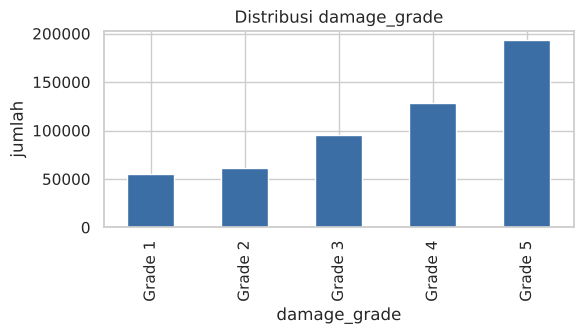

damage_grade
Grade 1    0.103
Grade 2    0.114
Grade 3    0.179
Grade 4    0.241
Grade 5    0.362
Name: proportion, dtype: float64

In [4]:
ax = train.damage_grade.value_counts().sort_index().plot.bar(color='#3b6ea5', figsize=(6,3.5))
ax.set_title('Distribusi damage_grade'); ax.set_ylabel('jumlah')
plt.tight_layout(); plt.savefig(FIG/'target_distribution.png', dpi=130); plt.show()
train.damage_grade.value_counts(normalize=True).sort_index().round(3)

Kelas tidak seimbang: Grade 5 (~36%) hampir 3,5x Grade 1 (~10%). Karena metrik Macro F1 memberi bobot sama pada tiap kelas, bobot probabilitas per kelas akan dituning di tahap modeling.

## 3. Fitur kategorik vs tingkat kerusakan

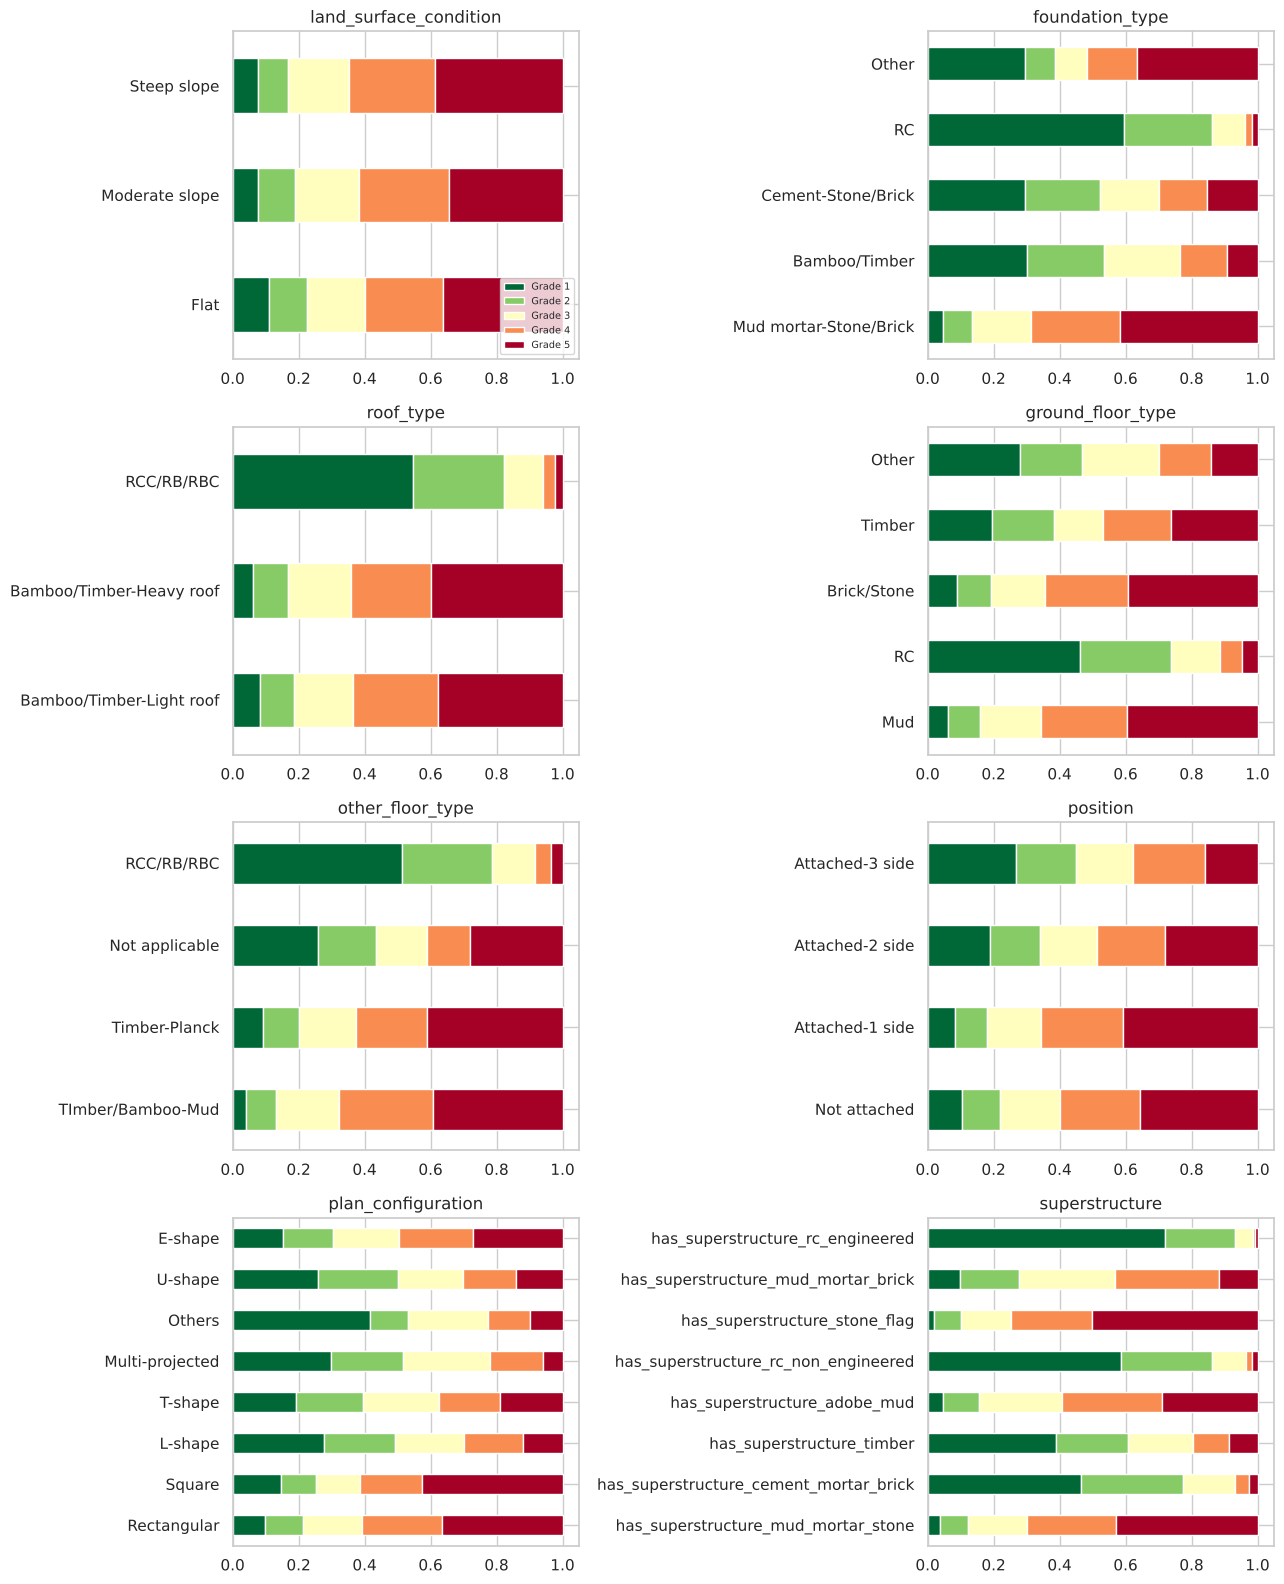

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(13, 16))
for ax, c in zip(axes.ravel(), CATEGORICAL_COLS):
    ct = pd.crosstab(train[c], train.damage_grade, normalize='index')
    ct = ct.loc[train[c].value_counts().index[:8]]
    ct.plot.barh(stacked=True, ax=ax, colormap='RdYlGn_r', legend=False)
    ax.set_title(c); ax.set_ylabel('')
axes[0,0].legend(loc='lower right', fontsize=7)
plt.tight_layout(); plt.savefig(FIG/'categorical_vs_damage.png', dpi=110); plt.show()

Material dan tipe lantai/fondasi sangat membedakan: bangunan dengan fondasi/lantai berbahan lumpur (mud mortar) dan atap berat cenderung rusak parah, sedangkan RC/semen cenderung Grade 1-3.

## 4. Fitur numerik

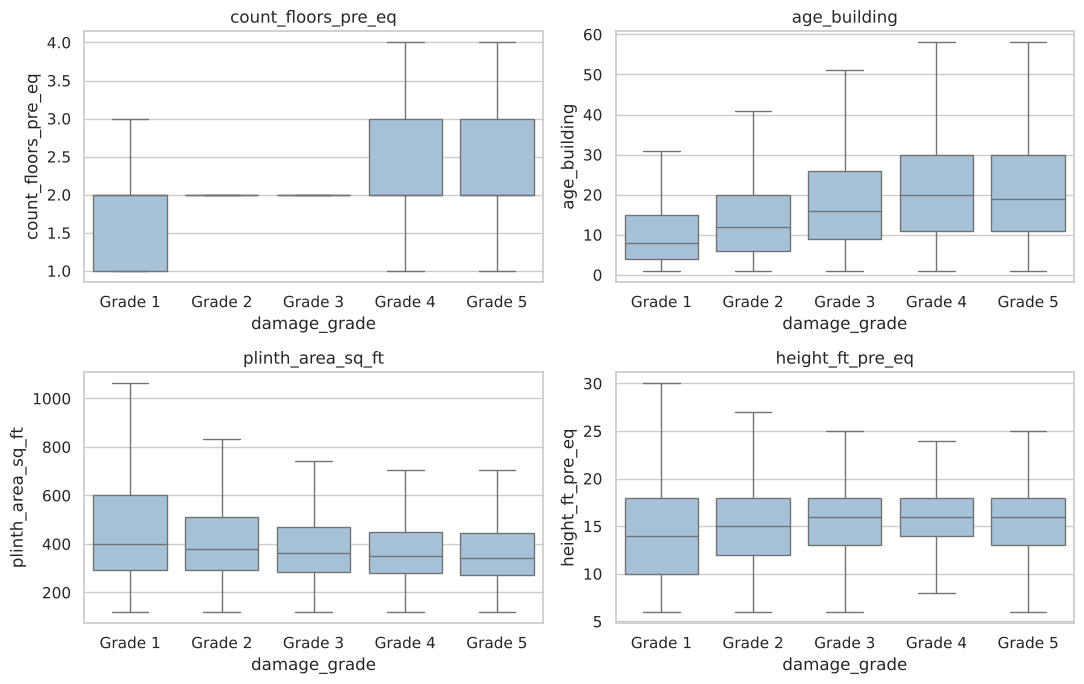

In [6]:
num = ['count_floors_pre_eq','age_building','plinth_area_sq_ft','height_ft_pre_eq']
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, c in zip(axes.ravel(), num):
    lo, hi = train[c].quantile([0.01, 0.99])
    sns.boxplot(data=train[train[c].between(lo, hi)], x='damage_grade', y=c, order=sorted(train.damage_grade.unique()), ax=ax, color='#9ec1e0', showfliers=False)
    ax.set_title(c)
plt.tight_layout(); plt.savefig(FIG/'numeric_vs_damage.png', dpi=120); plt.show()

Bangunan yang lebih tinggi dan lebih tua cenderung mengalami kerusakan lebih berat.

## 5. Lokasi geografis
`building_id` 12 digit memuat kode lokasi (2 digit pertama = district; 4 digit pertama dan 6 digit pertama berbeda dari `vdcmun_id`/`ward_id`, sehingga menambah informasi lokasi).

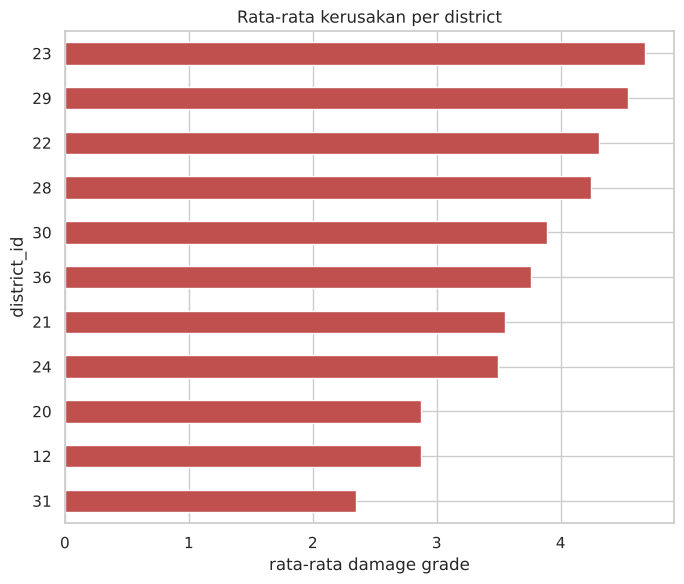

In [7]:
d = train.groupby('district_id').y.agg(['mean','size']).sort_values('mean')
ax = d['mean'].plot.barh(figsize=(7,6), color='#c0504d'); ax.set_xlabel('rata-rata damage grade'); ax.set_title('Rata-rata kerusakan per district')
plt.tight_layout(); plt.savefig(FIG/'district_damage.png', dpi=120); plt.show()

In [8]:
b = train.building_id.astype(str).str.zfill(12)
train['b_vdc'] = b.str[:4].astype(int)
print('kecocokan district:', (b.str[:2].astype(int) == train.district_id).mean())
print('kecocokan vdc :', (train.b_vdc == train.vdcmun_id).mean())
print('std rata-rata damage antar vdcmun_id:', train.groupby('vdcmun_id').y.mean().std().round(3), '| antar b_vdc:', train.groupby('b_vdc').y.mean().std().round(3))

kecocokan district: 1.0
kecocokan vdc : 0.011155371017779985
std rata-rata damage antar vdcmun_id: 0.76 | antar b_vdc: 0.814


Rata-rata kerusakan sangat bervariasi antar-district (epicenter di Gorkha/Sindhupalchok), sehingga kode lokasi menjadi prediktor penting. Ini terkonfirmasi di modeling (Macro F1 naik dari 0.45 ke 0.54 ketika fitur lokasi ditambahkan).